# Lab 1: K-nn From Scratch

This lab involves creating the machine learning algorithm K-nearest neighbour from scratch.

## Imports

In [1]:
import matplotlib.pyplot as plt
import data_functions as df
import classification_functions as cf
import numpy as np

# Basic task
## create the basic algorith 

## Read data and save in appropriate format

Give the function `read_data_points` the path to the data files. The function processes the data from strings into usable data in the form of NDArray.

In [2]:
pichu = df.read_data_points("data/pichu.txt")
pikachu = df.read_data_points("data/pikachu.txt")
pikachu[:3]

array([[18.13777226, 44.95149357],
       [26.64866183, 41.49878058],
       [26.18052443, 39.38100084]])

## Plot all points with different colors in the same window

Plot all pikachu and pichu points with matplotlib using an OOP approach.

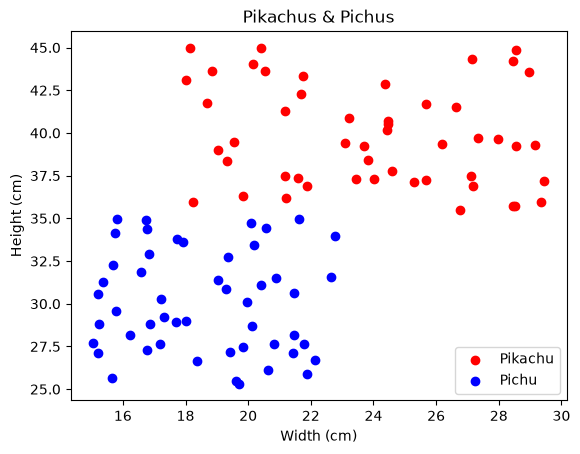

In [3]:
fig, ax = plt.subplots()

ax.scatter(pikachu[:, 0], pikachu[:, 1], color="red", label="Pikachu")
ax.scatter(pichu[:, 0], pichu[:, 1], color="blue", label="Pichu")

ax.set(xlabel="Width (cm)", ylabel="Height (cm)", title="Pikachus & Pichus")
ax.legend(loc="lower right")

## Read test points

Feed a one-row file of test data into `read_test_points`. The function processes the test points into a usable NDArray.

In [4]:
test_points = df.read_test_points("data/test_points.txt")
print(test_points[:2])

[[25. 35.]
 [15. 14.]]


## Distance between pikachu/pichu and test points

Loop through all test points, calculate the distance to each pikachu/pichu point and return a list of tuples for every point as distance, pokemon name.

In [ ]:
for test_point in test_points:
    distances = cf.calculate_test_point(test_point, pichu, pikachu)

Pikachu


## Get closest point

In [6]:
print(distances[0][1])

Pikachu


# Main tasks

## 1. User input

Asks the user for two test points (width, height) and stores the distances from each point as a list.

In [13]:
while(True): 
    try:
        width, height = cf.request_testpoint()
        distances = cf.calculate_test_point((width, height), pichu, pikachu)
        break
    except ValueError as e:
        print(e)

print(f"Your given test point is classified as: {distances[0][1]}")

Your given test point is classified as: Pichu


## 2. K-Nearest Neighbours

Classify the test point using the nearest K distances (neighbours).

In [8]:
classification = cf.knn(5, distances)
classification

'Pichu'

# Bonus Tasks

## 3. Shuffle and split data

Use ´split_data´ to randomly shuffle the data. Split the data into five test points and the remaining points.

In [9]:
pikachu_train, pikachu_test = df.split_data(pikachu)
pichu_train, pichu_test = df.split_data(pichu)

## 4. Calculate accuracy

Use `calculate_accuracy` to calculate the classification accuracy of test points compared to training data.

In [10]:
res = cf.calculate_accuracy(pikachu_train, pikachu_test, pichu_train, pichu_test)
print(f"{res * 100}%")

100.0%


## Shuffle the data repeatedly for more accurate results

Shuffle the data many times and calculate the mean for more accurate results.

In [11]:
shuffles = 1000

results = []

for _ in range(shuffles):
    pikachu_train, pikachu_test = df.split_data(pikachu)
    pichu_train, pichu_test = df.split_data(pichu)

    res = cf.calculate_accuracy(pikachu_train, pikachu_test, pichu_train, pichu_test)
    results.append(res)

print(f"{(sum(results) / len(results) * 100):.2f}% accuracy over {shuffles} shuffles")

98.94% accuracy over 1000 shuffles
